# Lab: A Quantum Random Number Generator (QRNG) — Build It, Run It on IBM Quantum Hardware, Test It

**Qiskit Fall Fest 2026 · AstraCode Hackathon · Project 4**

Team: Temi (quantum engine) · Mike (statistics) · Evans (presentation)

A classical computer can only *imitate* randomness with a formula. A qubit can produce it physically: put it in an equal superposition, measure it, and the outcome is 0 or 1 with probability 1/2 each. In this notebook we **(1)** build that circuit with Qiskit and follow the Qiskit patterns workflow (Map → Optimize → Execute → Post-process), **(2)** run it on a **real IBM quantum computer** and turn the bits into numbers from 0 to 255, and **(3)** test those numbers with statistics against Python's random generator and a noisy simulator.

# Table of Contents

* [Before you begin](#before)
* [1. One qubit, one random bit](#onequbit)
* [2. Build, run and scale up the QRNG with Qiskit patterns](#qrng)
    - [2.1 Step 1: Map the problem to a quantum-native format](#step1)
    - [2.2 Optimize the circuits for a backend](#optimize)
    - [2.3 Execute using the quantum primitives](#execute)
    - [2.4 Post-process & analyze the results](#post)
    - [2.5 Repeat the process on real quantum hardware](#repeat)
    - [2.6 Scale to more qubits](#scale)
* [3. Load and validate the data](#load)
* [4. The statistical toolkit](#tools)
* [5. Run the tests: quantum hardware vs. Python vs. noisy simulator](#tests)
* [6. Can you tell them apart by eye?](#eye)
* [7. Noise Detective: why is the simulator lopsided?](#noise)
* [8. The three questions](#questions)
* [Conclusions](#conclusions)

## Before you begin <a id="before"></a>

Install the packages once (skip if you already have them):

```
pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc
```

Written for Qiskit 2.x. Choose the kernel **Python 3** and **run the cells from top to bottom**, starting with the Setup check below. When the key prompt appears, press Enter to skip live hardware (the notebook then uses the real hardware run we saved) or paste your IBM key to run live.

**Data safety:** the saved real-hardware run is embedded below and is only *read*. A live run is kept in memory and written to a *separate* file, `live_run_latest.json`; it can never overwrite the saved dataset.

### Setup check
Run this cell first. It checks that the packages are installed (installing any that are missing) and that the Qiskit version is new enough. If it prints `READY`, everything below will run.

In [1]:
import importlib, subprocess, sys

REQUIRED = {"qiskit": "qiskit", "qiskit_aer": "qiskit-aer", "qiskit_ibm_runtime": "qiskit-ibm-runtime",
            "matplotlib": "matplotlib", "pylatexenc": "pylatexenc"}

missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing), "(this can take a minute)")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    importlib.invalidate_caches()

import qiskit, qiskit_aer, qiskit_ibm_runtime
from importlib.metadata import version
major = int(qiskit.__version__.split(".")[0])
print(f"Python {sys.version.split()[0]} | qiskit {qiskit.__version__} | qiskit-aer {version('qiskit-aer')} | qiskit-ibm-runtime {version('qiskit-ibm-runtime')}")
if major < 2:
    raise RuntimeError("This notebook needs Qiskit 2.x. Run: pip install -U qiskit qiskit-aer qiskit-ibm-runtime, then restart the kernel.")
try:
    from qiskit_ibm_runtime import SamplerV2
    from qiskit_aer import AerSimulator
except ImportError as err:
    raise RuntimeError("Please upgrade: pip install -U qiskit-aer qiskit-ibm-runtime, then restart the kernel.") from err
print("READY")

Python 3.13.18 | qiskit 2.6.2 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.52.0
READY


## Imports

In [2]:
import json, math, random
from collections import Counter
from pathlib import Path
from statistics import NormalDist
from datetime import datetime

import qiskit
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("Qiskit", qiskit.__version__)

Qiskit 2.6.2


### Saved measurements
These are the results we measured earlier. Nothing here is generated by the notebook.

In [3]:
# Saved measurements, embedded so this notebook runs on its own (no extra files needed).
# HARDWARE = one real run on IBM Quantum hardware. NOISY = a simulation with ASSUMED noise (not measured).
HARDWARE = {
    "source": 'ibm_marrakesh', "job_id": 'dbplvroqtr0c738elbe0', "created": '2026-11-10T21:18:50.516032', "n_qubits": 8,
    "bits": (
    "0101111110000001000001001000011001010101011001110010001101100101000011010010010100111001010000000001"
    "1011111110010110010101110001011000010001000111110110011110011011111100001101000110101101111010101001"
    "0101011110111011111011100101011000000001110010000001111011110000111110110101010100100100001010110101"
    "1010011111110110011001010101010001011000000001011111111100101101101111000111001101110111100100111011"
    "1000101101010010000111010110111011010110001111001100001000010000001000011111011101110010110111111001"
    "1001101000111011111111110110111001011111001010110001000110011001110111100001010110010100100101100000"
    "0100110111011001000010111110010110011111000000110010001100101100111000100110010011111000000100101010"
    "0101000101100111111111011001010100111101111110000010011111110110011000000010011001010100011111100111"
    "0011010111111110010111010101001101011101101000010001011010011001101011110010010010101110100100111000"
    "0010010110010001000101010110001100111001000011010010101110110111000101010110011100010110010001100100"
    ),
}
NOISY = {
    "source": "aer_noisy (simulation, assumed noise)", "job_id": None, "created": '2026-11-10T20:45:49.804836', "n_qubits": 8,
    "bits": (
    "0011101000101100101100001010000101000010000110110001100001111001000101001010000000000011010011000100"
    "0010110101101111001010100001100000110001000011000010001101010001100001011010000100011010010111110010"
    "0111111000001100000110000010001011011111001111001101111001010000011101100010111011110100000000000100"
    "0001001010100001110011100110010001010101100001111100001010110001001110001100110111001011100011110100"
    "1001010001010101000100011010011101110110111100000010101000011100111100110000011101111000101111110111"
    "0010001100010011011101011001001011001010110000000010001010001101101010010010001011101000110001011111"
    "0010100000001110101101001111001001110101001110101001100000000100000101100110001010110100010100000011"
    "0011010011101111011111000101010110111111100010110100011110111110010001010111101011110110110001011011"
    "0110101110011110001001010111001010001111100011010000011000000100000111001000001100000101101111111100"
    "1011010001011110110011111101111111100010100010011000000111001000001010101001011001010111000000010011"
    ),
}
for d in (HARDWARE, NOISY):
    d["bits"] = [int(ch) for ch in d["bits"]]
    assert set(d["bits"]) <= {0, 1} and len(d["bits"]) == 1000
print("Saved hardware run :", HARDWARE["source"], "| job", HARDWARE["job_id"], "|", len(HARDWARE["bits"]), "bits")
print("Saved noisy sim    :", NOISY["source"], "|", len(NOISY["bits"]), "bits")

Saved hardware run : ibm_marrakesh | job dbplvroqtr0c738elbe0 | 1000 bits
Saved noisy sim    : aer_noisy (simulation, assumed noise) | 1000 bits


### Connect to IBM Quantum (optional)
To execute on a real quantum computer you need an IBM Quantum account (the free/student plan works).

1. Go to the [IBM Quantum Platform](https://quantum.cloud.ibm.com/) and create your **API key**.
2. Create an **instance** and copy its **CRN**.
3. Run the next cell and paste both when prompted. They are typed with `getpass` (hidden), **never printed and never saved** in this notebook.
4. **No key? Just press Enter.** Every live-hardware cell is skipped and the notebook uses the real hardware run we already saved (job ID shown in the outputs).

<div class="alert alert-block alert-warning">

⚠️ **Note:** Treat your API key like a password. Never paste it into a cell that you then share.
</div>

In [4]:
import getpass

token = getpass.getpass("IBM API key (press Enter to skip live hardware): ").strip()
instance = getpass.getpass("IBM instance CRN (press Enter to skip): ").strip() if token else ""

service = None
if token:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=instance or None)
        print("Connected to IBM Quantum.")
    except Exception as err:          # do not echo the key
        print("Could not connect:", type(err).__name__, "- continuing with saved hardware data.")
else:
    print("No key entered: live hardware cells will be skipped, saved real-hardware data is used.")
del token, instance

No key entered: live hardware cells will be skipped, saved real-hardware data is used.


# 1. One qubit, one random bit <a id="onequbit"></a>

Start with a single qubit in $|0\rangle$ and apply a **Hadamard** gate:

$$ H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} $$

The qubit is now in an *equal superposition*. When measured, the Born rule gives 0 or 1 with probability $\left|\tfrac{1}{\sqrt{2}}\right|^2 = 50\%$ each. Which one you get cannot be predicted by any formula, because it is not hidden in a seed: it is the physics of the measurement.

Statevector: Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
Probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


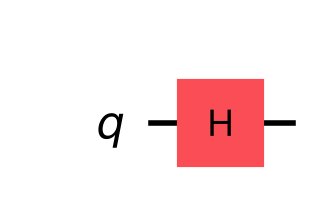

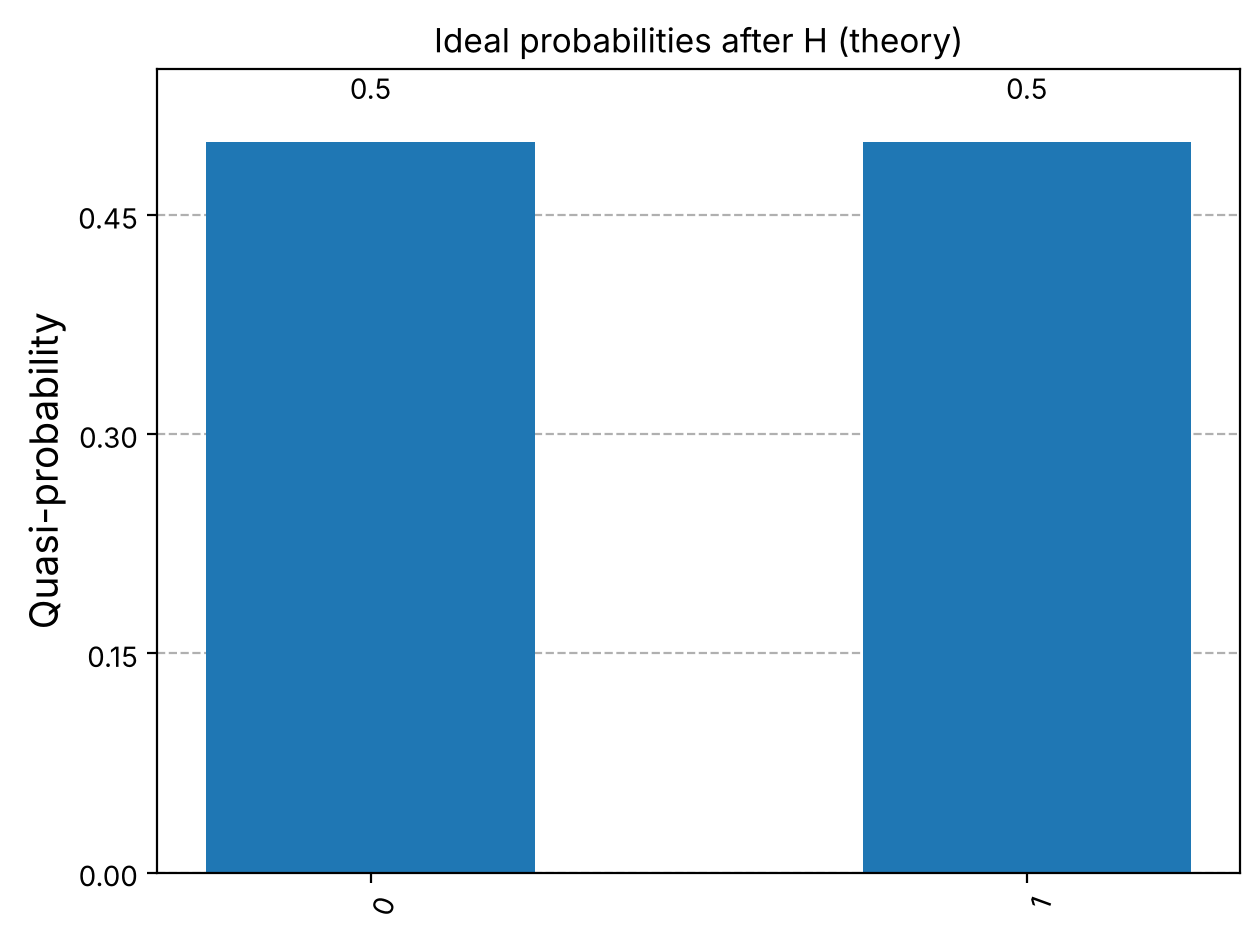

In [5]:
qc1 = QuantumCircuit(1)
qc1.h(0)

sv = Statevector(qc1)
print("Statevector:", sv)
print("Probabilities:", sv.probabilities_dict())
display(qc1.draw("mpl"))
display(plot_histogram(sv.probabilities_dict(), title="Ideal probabilities after H (theory)"))

# 2. Build, run and scale up the QRNG with Qiskit patterns <a id="qrng"></a>

A single qubit gives 1 bit per run. To collect bits faster we put **8 qubits** in superposition at once, so every shot (one run of the circuit) returns **8 random bits = one number from 0 to 255**. We take 125 shots to get 1,000 bits.

We follow the [Qiskit patterns](https://quantum.cloud.ibm.com/docs/guides/intro-to-patterns) workflow: **Map → Optimize → Execute → Post-process**.

<div class="alert alert-info">

The Qiskit SDK uses little-endian bit ordering: classical bit 0 is the **right-most** character of a result string. We reverse each shot string so that qubit 0 is the first bit.
</div>

## 2.1 Step 1: Map the problem to a quantum-native format <a id="step1"></a>

The circuit is one Hadamard on every qubit followed by measurement of every qubit.

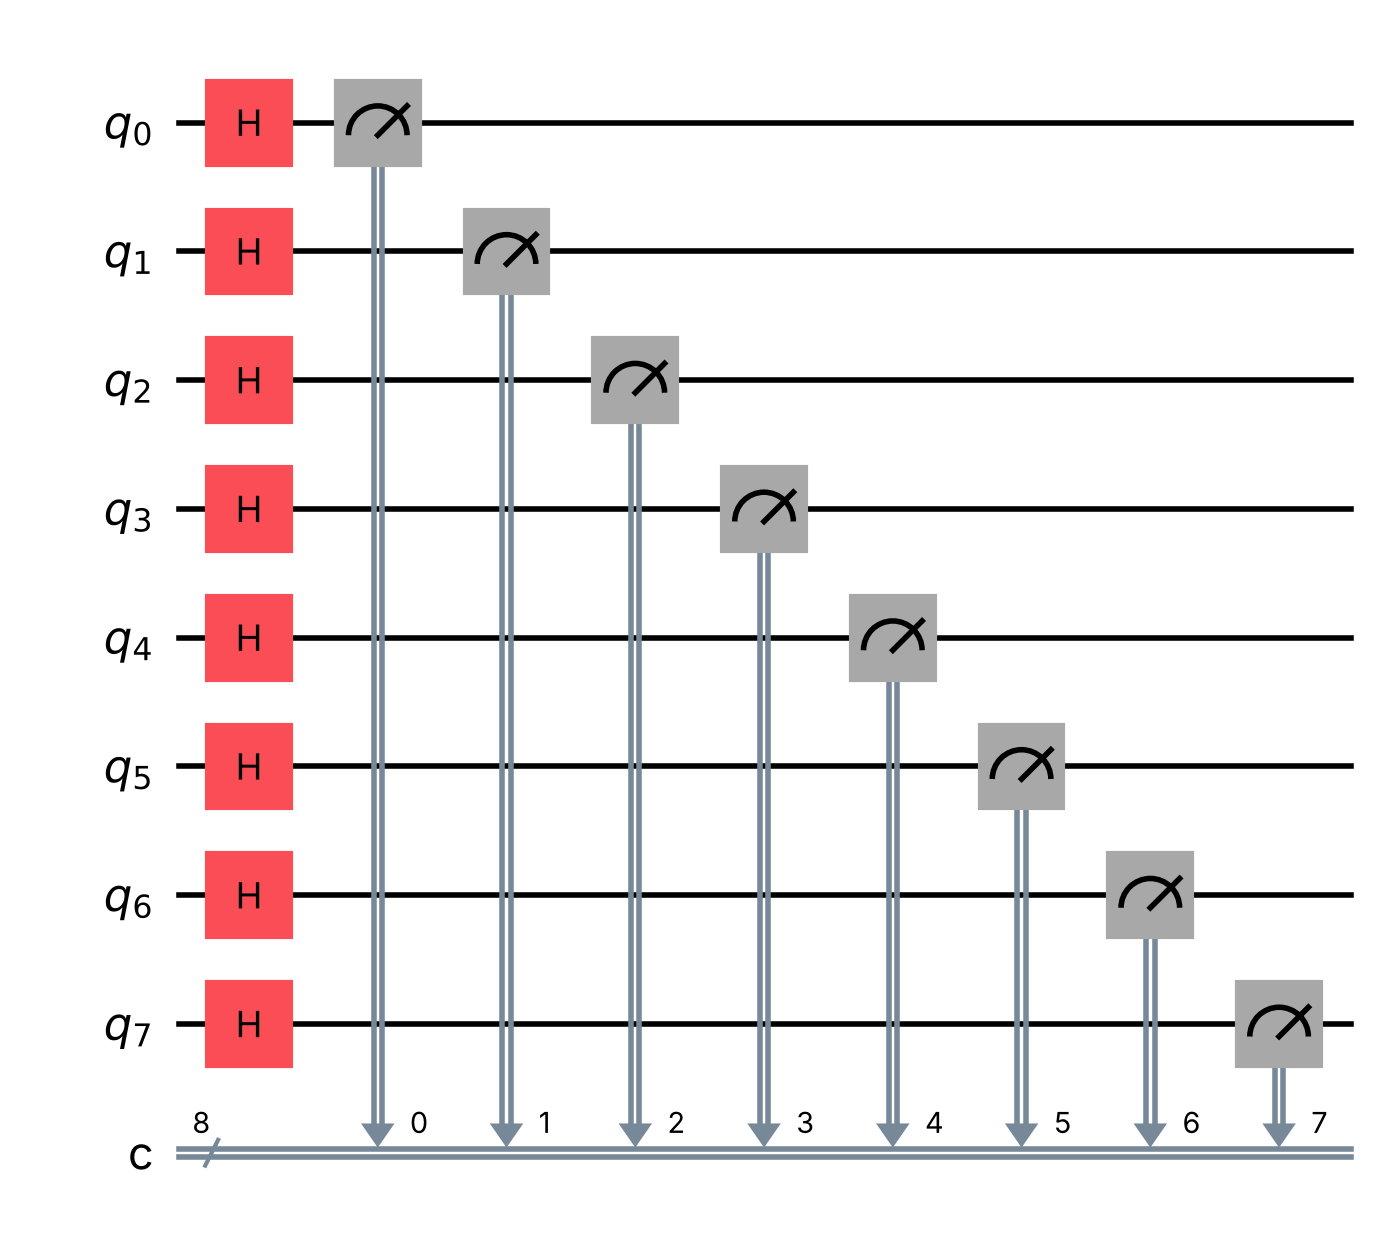

In [6]:
N_QUBITS = 8
N_BITS = 1000
SHOTS = N_BITS // N_QUBITS          # 125 shots x 8 qubits = 1,000 bits


def build_qrng_circuit(n_qubits: int = N_QUBITS) -> QuantumCircuit:
    """Hadamard on every qubit, then measure every qubit into classical register 'c'."""
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(range(n_qubits))
    qc.measure(range(n_qubits), range(n_qubits))
    return qc


qc = build_qrng_circuit()
qc.draw("mpl")

## 2.2 Optimize the circuits for a backend <a id="optimize"></a>

Real devices only run a small set of native gates on specific qubits, so the circuit is transpiled to that *instruction set architecture* (ISA). We prepare three backends.

#### Option 1: Real Hardware (needs the optional key above)

In [7]:
backend = None
if service is not None:
    try:
        backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
        print(f"Least busy real backend: {backend.name} ({backend.num_qubits} qubits)")
    except Exception as err:
        print("Could not pick a backend:", type(err).__name__)
else:
    print("Skipped: no IBM key. Saved real-hardware data (", HARDWARE["source"], ") is used in section 2.5.")

Skipped: no IBM key. Saved real-hardware data ( ibm_marrakesh ) is used in section 2.5.


#### Option 2: AerSimulator (ideal, noiseless)
A classical program that imitates a perfect quantum computer. Its 'randomness' comes from a classical pseudo-random generator, so it is **not** a source of true quantum randomness.

In [8]:
backend_aer = AerSimulator(seed_simulator=42)
print("Ideal simulator ready:", backend_aer.name)

Ideal simulator ready: aer_simulator


#### Option 3: Noisy AerSimulator (assumed noise)
We add imperfections *we chose ourselves*: 2% depolarizing error on each Hadamard and an asymmetric readout error ($P(1|0)=5\%$, $P(0|1)=12\%$). These numbers are **assumptions, not measurements of any real device**; we use this simulator for the Noise Detective in section 7.

In [9]:
P_GATE = 0.02
P_1_GIVEN_0, P_0_GIVEN_1 = 0.05, 0.12

noise = NoiseModel()
noise.add_all_qubit_quantum_error(depolarizing_error(P_GATE, 1), ["h"])
noise.add_all_qubit_readout_error(ReadoutError([[1 - P_1_GIVEN_0, P_1_GIVEN_0], [P_0_GIVEN_1, 1 - P_0_GIVEN_1]]))
backend_noisy = AerSimulator(noise_model=noise, seed_simulator=42)
print("Noisy simulator ready (assumed noise).")

Noisy simulator ready (assumed noise).


Transform the circuit for the ideal simulator (the same call is used for real hardware in section 2.5):

In [10]:
pm_aer = generate_preset_pass_manager(backend=backend_aer, optimization_level=1)
isa_circuit_aer = pm_aer.run(qc)
print("Gates after transpiling:", dict(isa_circuit_aer.count_ops()), "| depth:", isa_circuit_aer.depth())

Gates after transpiling: {'h': 8, 'measure': 8} | depth: 2


## 2.3 Execute using the quantum primitives <a id="execute"></a>

The **Sampler** primitive runs the circuit many times and returns the measured bitstring of every shot. We keep every shot in order, which is what lets us turn them into numbers later.

In [11]:
def run_sampler(isa_circuit, backend, shots=SHOTS):
    """Run on any backend; return (per-shot bitstrings, job id if available)."""
    sampler = Sampler(mode=backend)
    job = sampler.run([isa_circuit], shots=shots)
    result = job.result()
    shot_strings = result[0].data.c.get_bitstrings()      # one string per shot, in order
    try:
        jid = job.job_id()
    except Exception:
        jid = None
    return shot_strings, jid


shots_aer, _ = run_sampler(isa_circuit_aer, backend_aer)
print(len(shots_aer), "shots; first three:", shots_aer[:3])

125 shots; first three: ['11110010', '00100011', '11001010']


## 2.4 Post-process & analyze the results <a id="post"></a>

Post-processing: reverse each shot string (little-endian → qubit 0 first), join all shots into one bit stream, then group every 8 bits into a number 0–255.

Ideal simulator (classical imitation): 1000 bits, 492 ones (49.2%), 125 numbers, first ten: [79, 196, 83, 66, 73, 134, 56, 67, 22, 229]


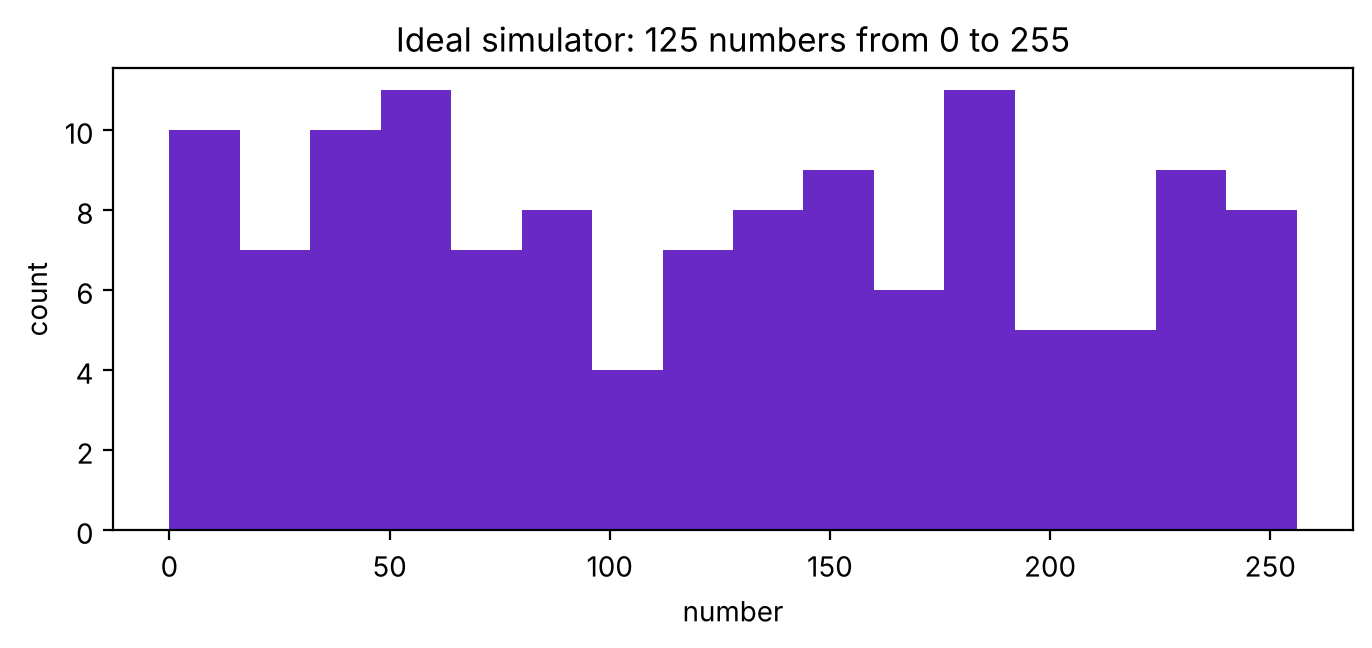

In [12]:
def shots_to_bits(shot_strings):
    return [int(ch) for s in shot_strings for ch in s[::-1]]


def bits_to_numbers(bits, n_qubits=N_QUBITS):
    return [int("".join(map(str, bits[i:i + n_qubits])), 2) for i in range(0, len(bits) - n_qubits + 1, n_qubits)]


def summarize(label, bits):
    nums = bits_to_numbers(bits)
    print(f"{label}: {len(bits)} bits, {sum(bits)} ones ({sum(bits)/len(bits):.1%}), {len(nums)} numbers, first ten: {nums[:10]}")
    return nums


bits_aer = shots_to_bits(shots_aer)
nums_aer = summarize("Ideal simulator (classical imitation)", bits_aer)

plt.figure(figsize=(8, 3))
plt.hist(nums_aer, bins=16, range=(0, 256), color="#6929c4")
plt.title("Ideal simulator: 125 numbers from 0 to 255")
plt.xlabel("number"); plt.ylabel("count"); plt.show()

Same circuit on the **noisy** simulator, with 2,500 shots (20,000 bits) because a bias of a few percent is hidden by chance in only 1,000 bits. A lopsided count of 1s is the fingerprint of the readout error we assumed (expected ones ≈ 0.5·(1−0.12) + 0.5·0.05 = 46.5%):

In [13]:
pm_noisy = generate_preset_pass_manager(backend=backend_noisy, optimization_level=1)
shots_noisy, _ = run_sampler(pm_noisy.run(qc), backend_noisy, shots=2500)   # 20,000 bits: enough to see the bias clearly
bits_noisy = shots_to_bits(shots_noisy)
summarize("Noisy simulator (assumed noise)", bits_noisy)
print("Expected fraction of ones from the noise model: 46.5%")

Noisy simulator (assumed noise): 20000 bits, 9233 ones (46.2%), 2500 numbers, first ten: [235, 22, 178, 12, 54, 19, 240, 122, 190, 66]
Expected fraction of ones from the noise model: 46.5%


Awesome! You have run the QRNG circuit on classical simulators. They are useful to test the code, but **only a real measurement of a real qubit produces true quantum randomness.** Let's do that next.

## 2.5 Repeat the process on real quantum hardware <a id="repeat"></a>

The code path is exactly the same: transpile for the backend, run the Sampler, post-process. If you entered an IBM key the cell below runs **live** on the least busy real device (a different chip may be picked each time, so results differ between runs). Otherwise it loads the real run we saved.

*Usage estimate: a few seconds of quantum time for 125 shots.*

In [14]:
live = None
if backend is not None:
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(qc)
    shots_hw, job_id = run_sampler(isa_circuit, backend)
    bits_live = shots_to_bits(shots_hw)
    live = {"source": backend.name, "job_id": job_id, "created": datetime.now().isoformat(),
            "n_qubits": N_QUBITS, "bits": "".join(map(str, bits_live))}
    with open("live_run_latest.json", "w") as f:        # separate file: saved dataset is never overwritten
        json.dump(live, f)
    print(f"LIVE run finished on {backend.name}, job {job_id}. Saved to live_run_latest.json")
else:
    print("No live run (no key). Using the saved real-hardware run below.")

No live run (no key). Using the saved real-hardware run below.


### Post-process the real-hardware bits

[SAVED] real hardware: ibm_marrakesh | job dbplvroqtr0c738elbe0
Real quantum hardware: 1000 bits, 512 ones (51.2%), 125 numbers, first ten: [95, 129, 4, 134, 85, 103, 35, 101, 13, 37]


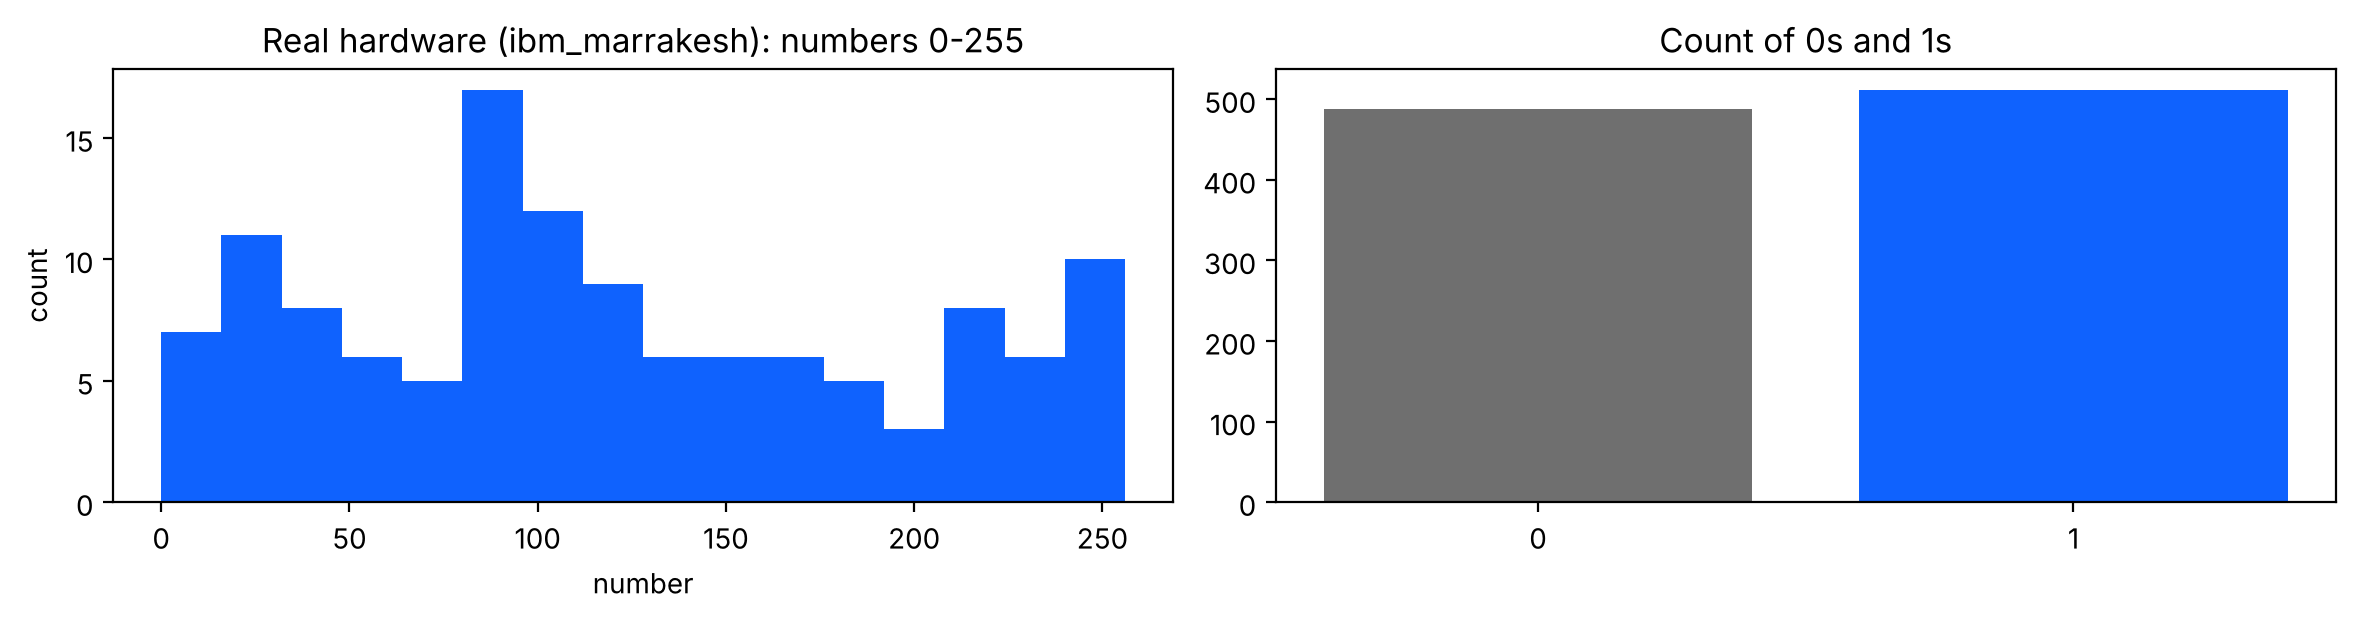

In [15]:
if live is not None:
    hw_bits, hw_name, hw_job, hw_kind = bits_live, live["source"], live["job_id"], "LIVE"
else:
    hw_bits, hw_name, hw_job, hw_kind = HARDWARE["bits"], HARDWARE["source"], HARDWARE["job_id"], "SAVED"

print(f"[{hw_kind}] real hardware: {hw_name} | job {hw_job}")
nums_hw = summarize("Real quantum hardware", hw_bits)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].hist(nums_hw, bins=16, range=(0, 256), color="#0f62fe")
ax[0].set_title(f"Real hardware ({hw_name}): numbers 0-255"); ax[0].set_xlabel("number"); ax[0].set_ylabel("count")
ax[1].bar(["0", "1"], [len(hw_bits) - sum(hw_bits), sum(hw_bits)], color=["#6f6f6f", "#0f62fe"])
ax[1].set_title("Count of 0s and 1s"); plt.tight_layout(); plt.show()

The real hardware bits look balanced: roughly half 0s and half 1s, with no visible pattern. Sections 3 to 8 below test this properly with statistics.

## 2.6 Scale to more qubits <a id="scale"></a>

More qubits per shot means more bits per shot, so fewer shots (less quantum time) are needed for the same amount of randomness. With $n$ qubits each shot gives a number in $[0, 2^n - 1]$. We check this on the ideal simulator:

In [16]:
print(f"{'qubits':>6} {'shots for 1000 bits':>20} {'numbers range':>15} {'ones fraction':>14}")
for n in (1, 2, 4, 8, 12, 16):
    qcn = build_qrng_circuit(n)
    shots_n = math.ceil(1000 / n)
    isa_n = generate_preset_pass_manager(backend=backend_aer, optimization_level=1).run(qcn)
    strings, _ = run_sampler(isa_n, backend_aer, shots=shots_n)
    b = shots_to_bits(strings)
    print(f"{n:>6} {shots_n:>20} {'0..' + str(2**n - 1):>15} {sum(b)/len(b):>14.3f}")

qubits  shots for 1000 bits   numbers range  ones fraction


     1                 1000            0..1          0.491


     2                  500            0..3          0.501


     4                  250           0..15          0.513


     8                  125          0..255          0.522
    12                   84         0..4095          0.509


    16                   63        0..65535          0.489


We use **8 qubits**: one byte (0–255) per shot, 125 shots for 1,000 bits, a shallow circuit (a single layer of H gates) that suffers little gate noise on real devices. The limit is not the circuit but the measurement: each readout can be slightly biased, which the statistics in sections 3 to 8 quantify.

# 3. Load and validate the data <a id="load"></a>

We compare three sources, each with 1,000 bits:

* **Real quantum hardware** (measured on an IBM quantum computer)
* **Python's `random` module** (a classical pseudo-random generator, seed 42)
* **Noisy simulator** (a classical simulation with assumed noise, *not* measured quantum data)

In [17]:
# Use the live hardware run if one was made in section 2.5, otherwise the saved real-hardware run.
if live is not None:
    HW_LABEL = f"Live hardware ({live['source']})"
    HW_BITS, HW_JOB = hw_bits, live["job_id"]
else:
    HW_LABEL = f"Real hardware ({HARDWARE['source']})"
    HW_BITS, HW_JOB = HARDWARE["bits"], HARDWARE["job_id"]

print("Hardware dataset:", HW_LABEL, "| job", HW_JOB, "|", len(HW_BITS), "bits")

Hardware dataset: Real hardware (ibm_marrakesh) | job dbplvroqtr0c738elbe0 | 1000 bits


# 4. The statistical toolkit <a id="tools"></a>

* **Monobit (frequency) test**: are 0s and 1s balanced? Gives a p-value; a very small p-value (below 0.05) is a red flag.
* **Runs test**: are streaks of equal bits the right length? Too few or too many runs suggests a pattern.
* **Longest run**: the longest streak of identical bits.
* **Shannon entropy**: close to 1.0 bit per bit means maximally unpredictable.
* **Lag-1 autocorrelation**: does one bit help predict the next? Close to 0 means no.

A p-value is the chance of seeing a result at least this lopsided *if the source were perfectly fair*. Passing means "no flaw found", **not** "proven random".

In [18]:
def bits_to_numbers(bits, n_qubits: int = 8) :
    """Convert a bitstream into integer values from contiguous n_qubit blocks."""
    bit_list = list(bits)
    if n_qubits <= 0:
        raise ValueError("n_qubits must be greater than 0")

    return [
        int("".join(str(bit) for bit in bit_list[i : i + n_qubits]), 2)
        for i in range(0, len(bit_list) - n_qubits + 1, n_qubits)
    ]



def shannon_entropy(bits) :
    """Return the Shannon entropy of a binary sequence in bits/bit."""
    if not bits:
        return 0.0

    p1 = sum(bits) / len(bits)
    p0 = 1.0 - p1
    entropy = 0.0
    for p in (p0, p1):
        if p > 0:
            entropy -= p * math.log2(p)
    return entropy



def count_runs(bits) -> int:
    """Count the number of runs in a binary sequence."""
    if not bits:
        return 0

    runs = 1
    for previous, current in zip(bits, bits[1:]):
        if previous != current:
            runs += 1
    return runs



def run_length_distribution(bits) :
    """Count the frequency of run lengths in the bitstream."""
    if not bits:
        return {}

    lengths = []
    current_length = 1
    for previous, current in zip(bits, bits[1:]):
        if previous == current:
            current_length += 1
        else:
            lengths.append(current_length)
            current_length = 1
    lengths.append(current_length)

    return dict(sorted(Counter(lengths).items()))



def monobit_frequency_test(bits) :
    """Perform the monobit frequency test using a standard normal approximation."""
    n = len(bits)
    if n == 0:
        raise ValueError("Cannot run monobit test on an empty bit list.")

    ones = sum(bits)
    zeros = n - ones
    p_hat = ones / n

    # For a fair source, the test statistic is approximately normal.
    # z = |2*ones - n| / sqrt(n)
    z_score = abs(2 * ones - n) / math.sqrt(n)
    p_value = 2 * (1.0 - NormalDist().cdf(z_score))

    return {
        "n_bits": n,
        "ones": ones,
        "zeros": zeros,
        "proportion_ones": p_hat,
        "expected_proportion": 0.5,
        "z_score": z_score,
        "p_value": p_value,
    }



def runs_test(bits) :
    """Summarize run structure as a basic independence test for binary randomness."""
    n = len(bits)
    if n == 0:
        raise ValueError("Cannot run runs test on an empty bit list.")

    total_runs = count_runs(bits)
    transitions = total_runs - 1
    run_lengths = run_length_distribution(bits)

    return {
        "n_bits": n,
        "total_runs": total_runs,
        "transitions": transitions,
        "transition_rate": transitions / max(n - 1, 1),
        "run_lengths": run_lengths,
    }



def autocorrelation(bits, lag: int = 1) :
    """Return the lag-k autocorrelation for a binary sequence."""
    if lag < 1:
        raise ValueError("lag must be at least 1")
    if len(bits) <= lag:
        return 0.0

    mean_value = sum(bits) / len(bits)
    numerator = sum(
        (bits[i] - mean_value) * (bits[i + lag] - mean_value)
        for i in range(len(bits) - lag)
    )
    denominator = sum((value - mean_value) ** 2 for value in bits[:-lag])

    if denominator == 0:
        return 0.0
    return numerator / denominator



def generate_python_random_bits(n_bits=1000, seed=None) :
    """Generate a baseline bitstream using Python's `random` module."""
    rng = random.Random(seed)
    return [rng.randint(0, 1) for _ in range(n_bits)]



def longest_run(bits):
    best = cur = 1
    for a, b in zip(bits, bits[1:]):
        cur = cur + 1 if a == b else 1
        best = max(best, cur)
    return best

# 5. Run the tests: quantum hardware vs. Python vs. noisy simulator <a id="tests"></a>

In [19]:
PY_BITS = generate_python_random_bits(1000, seed=42)
SOURCES = {HW_LABEL: HW_BITS, "Python random (seed 42)": PY_BITS, "Noisy simulator (assumed noise)": NOISY["bits"]}

rows = {}
print(f"{'source':<38}{'ones':>6}{'monobit p':>11}{'runs':>6}{'longest':>9}{'entropy':>9}{'autocorr':>10}")
for name, b in SOURCES.items():
    mono, rr = monobit_frequency_test(b), runs_test(b)
    rows[name] = dict(ones=mono["ones"], p=mono["p_value"], runs=rr["total_runs"], longest=longest_run(b),
                      entropy=shannon_entropy(b), ac=autocorrelation(b, 1))
    r = rows[name]
    print(f"{name:<38}{r['ones']:>6}{r['p']:>11.4f}{r['runs']:>6}{r['longest']:>9}{r['entropy']:>9.4f}{r['ac']:>10.4f}")
print("\nFor 1,000 fair bits we expect about 500 ones and about 500 runs.")

source                                  ones  monobit p  runs  longest  entropy  autocorr
Real hardware (ibm_marrakesh)            512     0.4479   507       10   0.9996   -0.0136
Python random (seed 42)                  514     0.3759   494       11   0.9994    0.0122
Noisy simulator (assumed noise)          464     0.0228   490       11   0.9963    0.0159

For 1,000 fair bits we expect about 500 ones and about 500 runs.


Reading the table: the hardware and Python rows both pass every test (monobit p-value above 0.05, entropy ≈ 1, autocorrelation ≈ 0). The noisy simulator is the odd one out, with too few ones and a monobit p-value flagged below 0.05, a fingerprint of the noise we put in (section 5).

# 6. Can you tell them apart by eye? <a id="eye"></a>

Below are the 125 numbers (0–255) from each source, grouped into 16 bins. A fair source gives roughly flat bars.

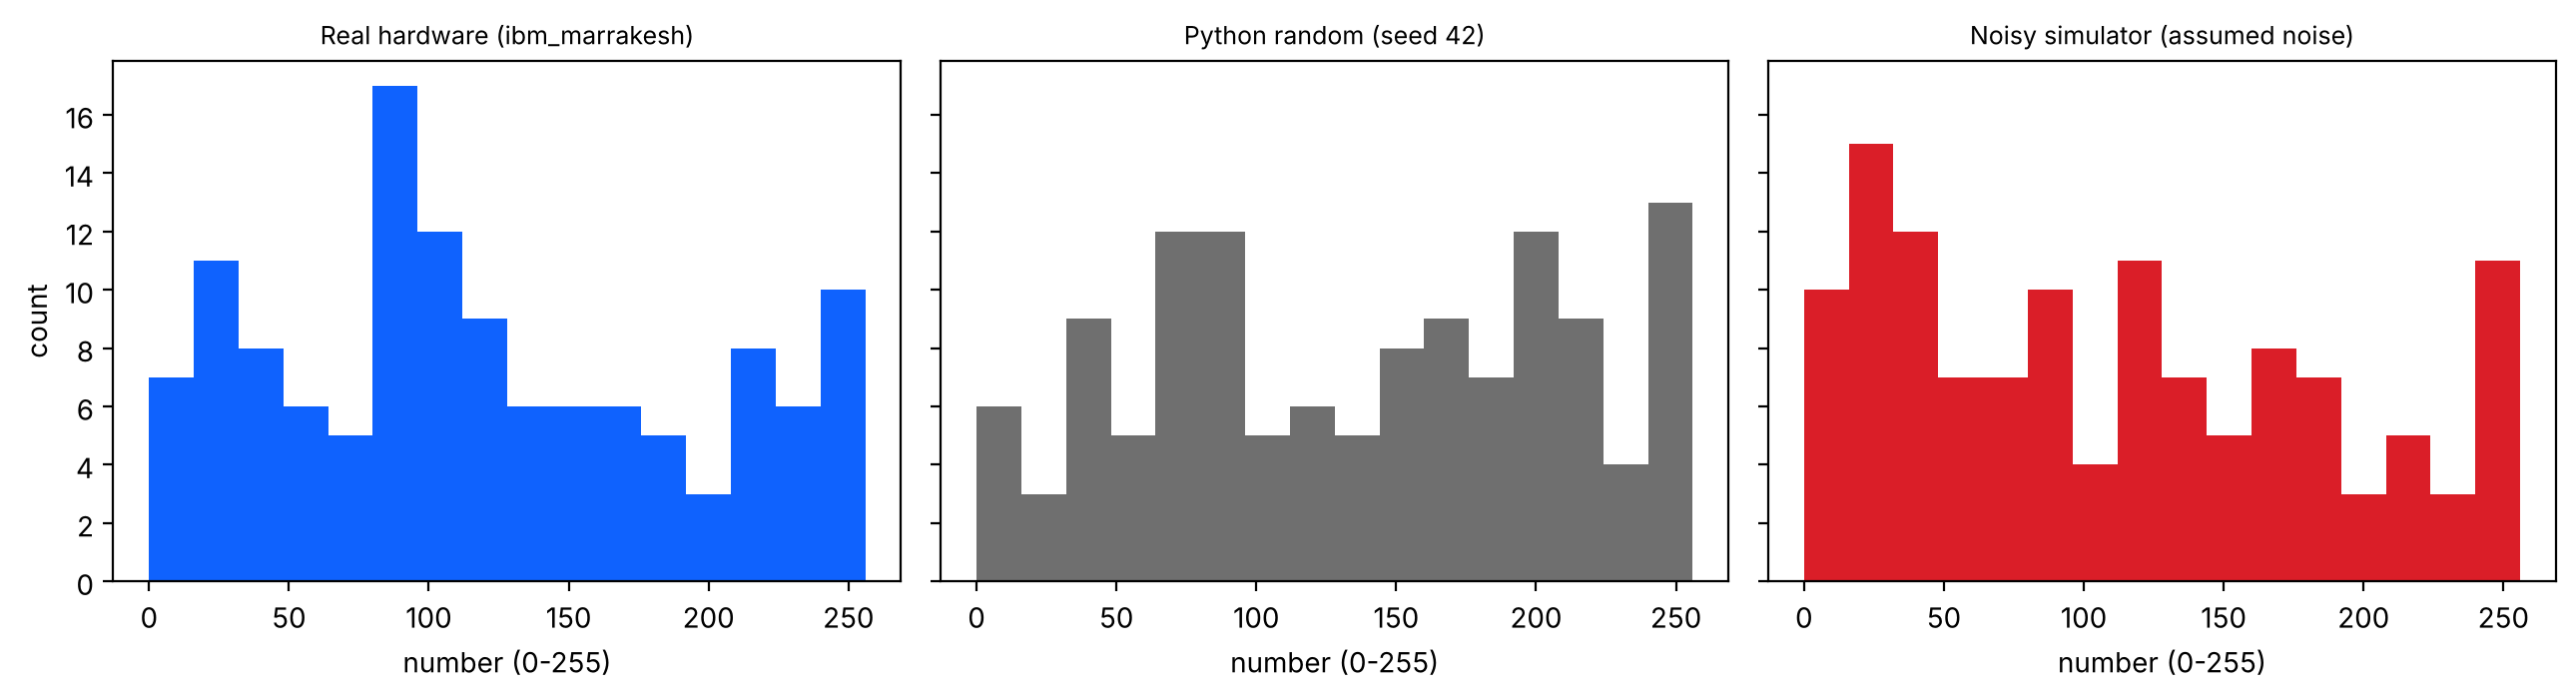

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, color, (name, b) in zip(axes, ["#0f62fe", "#6f6f6f", "#da1e28"], SOURCES.items()):
    ax.hist(bits_to_numbers(b), bins=16, range=(0, 256), color=color)
    ax.set_title(name, fontsize=9); ax.set_xlabel("number (0-255)")
axes[0].set_ylabel("count")
plt.tight_layout(); plt.show()

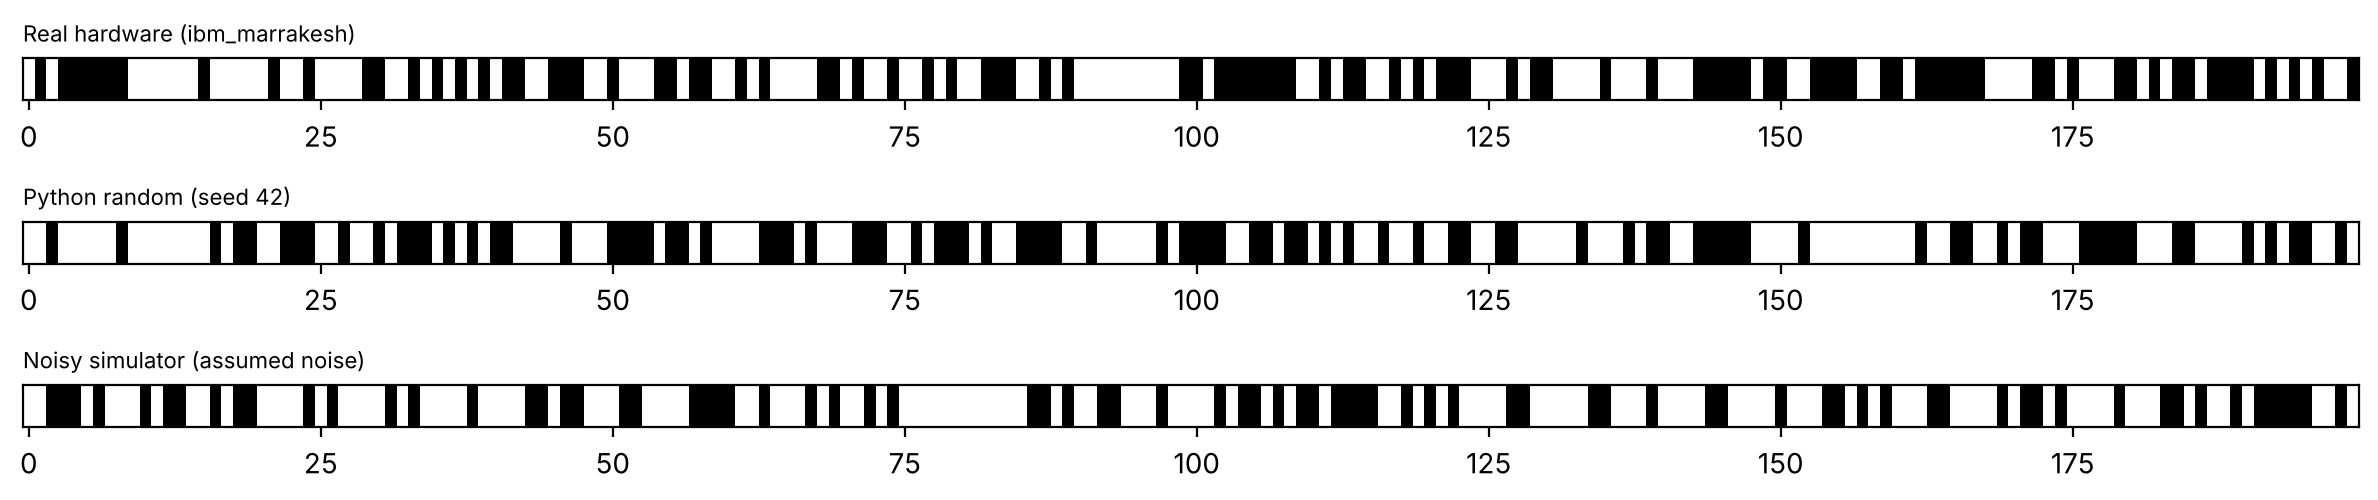

In [21]:
# Bit sequences: first 200 bits of each source (white = 0, filled = 1)
fig, axes = plt.subplots(3, 1, figsize=(12, 2.6))
for ax, (name, b) in zip(axes, SOURCES.items()):
    ax.imshow([b[:200]], aspect="auto", cmap="Greys"); ax.set_yticks([]); ax.set_title(name, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

# 7. Noise Detective: why is the simulator lopsided? <a id="noise"></a>

Our noisy simulator copies a real-world flaw: a qubit holding 1 is sometimes misread as 0 (12% of the time, a number **we chose**) while 0 is misread as 1 less often (5%). So we can *predict* the bias before looking at the data.

In [22]:
P_0_GIVEN_1, P_1_GIVEN_0 = 0.12, 0.05          # OUR assumed noise parameters, not measured from a device
expected = 0.5 * (1 - P_0_GIVEN_1) + 0.5 * P_1_GIVEN_0
observed = sum(NOISY["bits"]) / len(NOISY["bits"])
print(f"Predicted fraction of 1s from the noise model : {expected:.1%}")
print(f"Observed in the noisy simulation              : {observed:.1%}")
print(f"Observed in the hardware dataset              : {sum(HW_BITS)/len(HW_BITS):.1%}")

Predicted fraction of 1s from the noise model : 46.5%
Observed in the noisy simulation              : 46.4%
Observed in the hardware dataset              : 51.2%


The simulator's bias matches what its readout error predicts: **noise leaves a fingerprint** that statistics can detect. The real-hardware sample shows no such flaw at this sample size. Because the noise values were chosen by us, this demonstrates the *method*; it does not measure any real device's noise.

# 8. The three questions <a id="questions"></a>

In [23]:
hw, py, ny = rows[HW_LABEL], rows["Python random (seed 42)"], rows["Noisy simulator (assumed noise)"]
print(f"""1. Can you tell the quantum results from Python's by looking?
   No. Hardware: {hw['ones']} ones (monobit p={hw['p']:.3f}); Python: {py['ones']} ones (p={py['p']:.3f}). Both pass at the 0.05 level.
   Python's generator is designed to look random and 1,000 bits is too few to expose any pattern.
   The difference is where the randomness comes from, not how it looks.

2. What tests could check the numbers look random?
   Frequency (monobit), runs, longest run, entropy and autocorrelation. Passing means 'no flaw found', not 'proven random'.

3. How quantum is a simulator's randomness?
   Barely. A simulator is a classical program with a classical pseudo-random generator, like Python.
   Only the hardware run gets its randomness from a physical measurement. The noisy simulator ({ny['ones']} ones, p={ny['p']:.3f})
   shows how noise adds a detectable bias.""")

1. Can you tell the quantum results from Python's by looking?
   No. Hardware: 512 ones (monobit p=0.448); Python: 514 ones (p=0.376). Both pass at the 0.05 level.
   Python's generator is designed to look random and 1,000 bits is too few to expose any pattern.
   The difference is where the randomness comes from, not how it looks.

2. What tests could check the numbers look random?
   Frequency (monobit), runs, longest run, entropy and autocorrelation. Passing means 'no flaw found', not 'proven random'.

3. How quantum is a simulator's randomness?
   Barely. A simulator is a classical program with a classical pseudo-random generator, like Python.
   Only the hardware run gets its randomness from a physical measurement. The noisy simulator (464 ones, p=0.023)
   shows how noise adds a detectable bias.


# Conclusions <a id="conclusions"></a>

# Conclusions <a id="conclusions"></a>

In [24]:
print(f"""In this notebook we:
- built a QRNG circuit (H on every qubit, measure) and followed Map -> Optimize -> Execute -> Post-process;
- ran it on two classical simulators (ideal, and noisy with assumed noise) and on REAL IBM quantum hardware;
- turned the real run ({HW_LABEL}, job {HW_JOB}) into {len(HW_BITS)//8} numbers from 0 to 255;
- tested it against Python's random generator and the noisy simulator.

What we learned:
- Superposition plus measurement gives a bit that no formula can predict.
- With 1,000 bits, real hardware ({hw['ones']} ones, p={hw['p']:.3f}, longest run {hw['longest']}, entropy {hw['entropy']:.4f}) and Python ({py['ones']} ones, p={py['p']:.3f}) both look like a fair random source; these statistics cannot tell them apart.
- Our noisy simulator's bias matched what its assumed readout error predicted ({observed:.1%} vs {expected:.1%} expected), so noise leaves a fingerprint.
- A simulator is classical; only the hardware run has a physical quantum origin.

Honest limits: 1,000 bits is a small sample, the saved result is one hardware run, our noise numbers were chosen rather
than measured, and passing statistical tests shows 'no flaw found', never a proof of true randomness.""")

In this notebook we:
- built a QRNG circuit (H on every qubit, measure) and followed Map -> Optimize -> Execute -> Post-process;
- ran it on two classical simulators (ideal, and noisy with assumed noise) and on REAL IBM quantum hardware;
- turned the real run (Real hardware (ibm_marrakesh), job dbplvroqtr0c738elbe0) into 125 numbers from 0 to 255;
- tested it against Python's random generator and the noisy simulator.

What we learned:
- Superposition plus measurement gives a bit that no formula can predict.
- With 1,000 bits, real hardware (512 ones, p=0.448, longest run 10, entropy 0.9996) and Python (514 ones, p=0.376) both look like a fair random source; these statistics cannot tell them apart.
- Our noisy simulator's bias matched what its assumed readout error predicted (46.4% vs 46.5% expected), so noise leaves a fingerprint.
- A simulator is classical; only the hardware run has a physical quantum origin.

Honest limits: 1,000 bits is a small sample, the saved result is one hardwa